# kwtfs quickstart: the mode format, the regret reward, and why token cost matters

Everything above the **optional TPU section** runs on a CPU in a few seconds and needs only `numpy`
(plus `matplotlib` for the plots, if it is installed). It walks through:

1. the mode format and its strict parser;
2. the GRPO reward terms, including the exploit tests they were designed against;
3. a toy RLVR problem, solved with an exact softmax policy gradient, showing why a correctness-only reward
   drifts to the longest reasoning and how a token price changes that;
4. relabelling a small bundled sample of capability profiles at different token prices (λ).

The research post: https://tinevimbomusingadi.github.io/kwtfs-blog/

In [1]:
import json, pathlib, sys

# Use the package from this checkout even if it is not pip-installed.
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "kwtfs").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from kwtfs import format as fmt
from kwtfs import rewards as R

try:
    import matplotlib.pyplot as plt
except ImportError:  # plots are optional
    plt = None
print("modes:", fmt.MODES, "| genres:", fmt.GENRES, "| matplotlib:", plt is not None)

modes: ('jev', 'direct', 'cot') | genres: ('decision', 'compare', 'rubric', 'arith', 'wordproblem', 'knowledge') | matplotlib: True


## 1. The mode format

The system prompt carries a control, `Mode: auto|jev|direct|cot`. The completion starts with a genre tag and a
mode tag:

| mode | what the runtime does | example completion |
|---|---|---|
| `jev` | no generation: one forward step, read the option-letter logits | `<genre:compare><mode:jev>\nB` |
| `direct` | short generation (cap 48 tokens) | `<genre:arith><mode:direct>\n<answer>42</answer>` |
| `cot` | reasoning (cap 256 tokens); may hand off with `<mode:jev>` | `<genre:arith><mode:cot>\n6*7=42\n<answer>42</answer>` |

The parser is strict: anything off-format is invalid, and under a forced control the first mode must match it.

In [2]:
print(fmt.chat_prompt(fmt.render_question("Is 5975 more than 5974?", ["no", "yes"]), "auto"))

<|im_start|>system
Start with a genre tag, then exactly one mode tag.
Genres: <genre:decision>, <genre:compare>, <genre:rubric>, <genre:arith>, <genre:wordproblem>, <genre:knowledge>.
<mode:direct> answer immediately: <mode:direct>
<answer>VALUE</answer>
<mode:cot> think step by step in a few short lines, then end with <answer>VALUE</answer> or, when options are given, switch to <mode:jev>.
<mode:jev> pick one option letter only: <mode:jev>
B (only when options are given).
Mode: auto. If a mode is named, use it; if auto, choose the cheapest mode that will be correct.<|im_end|>
<|im_start|>user
Is 5975 more than 5974?

Options:
A) no
B) yes<|im_end|>
<|im_start|>assistant
<think>

</think>




In [3]:
examples = [
    # (completion, number of options shown, control)
    ("<genre:compare><mode:jev>\nB", 2, "auto"),
    ("<genre:arith><mode:direct>\n<answer>42</answer>", 0, "auto"),
    ("<genre:arith><mode:cot>\n6*7=42\n<answer>42</answer>", 0, "cot"),
    ("<genre:wordproblem><mode:cot>\n3 boxes of 4 is 12\n<mode:jev>\nC", 4, "auto"),
    ("<genre:compare><mode:jev>\nB", 2, "cot"),                      # disobeys a forced cot
    ("<genre:arith><mode:jev>\nB", 0, "auto"),                       # jev with no options shown
    ("<genre:arith><mode:direct>\n" + "x" * 150 + "<answer>42</answer>", 0, "auto"),  # direct hiding reasoning
    ("Sure! <mode:direct>\n<answer>42</answer>", 0, "auto"),         # text before the tag
]
print(f"{'completion':58} {'ctl':6} {'genre':12} {'modes':17} {'answer':6} valid")
for comp, n, ctl in examples:
    p = fmt.parse_tagged(comp, n, ctl)
    shown = comp.replace("\n", "\\n")
    shown = shown if len(shown) <= 56 else shown[:53] + "..."
    print(f"{shown:58} {ctl:6} {str(p.genre):12} {str(p.trace.modes):17} {str(p.trace.answer):6} {p.valid}")

completion                                                 ctl    genre        modes             answer valid
<genre:compare><mode:jev>\nB                               auto   compare      ('jev',)          B      True
<genre:arith><mode:direct>\n<answer>42</answer>            auto   arith        ('direct',)       42     True
<genre:arith><mode:cot>\n6*7=42\n<answer>42</answer>       cot    arith        ('cot',)          42     True
<genre:wordproblem><mode:cot>\n3 boxes of 4 is 12\n<m...   auto   wordproblem  ('cot', 'jev')    C      True
<genre:compare><mode:jev>\nB                               cot    compare      ('jev',)          B      False
<genre:arith><mode:jev>\nB                                 auto   arith        ('jev',)          None   False
<genre:arith><mode:direct>\nxxxxxxxxxxxxxxxxxxxxxxxxx...   auto   arith        ('direct',)       None   False
Sure! <mode:direct>\n<answer>42</answer>                   auto   None         ('direct',)       None   False


## 2. The reward terms

Tunix sums every public function in `kwtfs/rewards.py`:

* `correctness`: 1 for a valid, correct answer;
* `well_formed`: +0.1 valid, −0.2 off-format, **−1 for disobeying a forced mode**;
* `compute_cost`: −0.0005 per ~token (4 characters), capped at 0.3, **charged only on correct answers**;
* `faithful`: −0.05 per false `expression = number` line in the trace (capped at 0.2);
* `genre`: +0.05 for the right genre tag;
* `route_regret`: −β·(U* − U_chosen) under `auto`, from measured per-mode utilities U = p − λt, with β = 0.5
  annealed linearly to 0 during training.

In [4]:
TERMS = (R.correctness, R.well_formed, R.compute_cost, R.faithful, R.genre, R.route_regret)

def breakdown(comp, answer, options, control="auto", genre="arith", utilities=None):
    kw = dict(answer=[answer], options=[json.dumps(options)], control=[control],
              genre=[genre], utilities=[json.dumps(utilities) if utilities else None])
    return {f.__name__: round(f(None, [comp], **kw)[0], 4) + 0.0 for f in TERMS}  # + 0.0: no "-0.0"

def total(*args, **kwargs):
    return round(sum(breakdown(*args, **kwargs).values()), 4)

long_right = "<genre:arith><mode:cot>\n" + "4682*2=9364\n" * 20 + "<answer>9364</answer>"
short_wrong = "<genre:arith><mode:direct>\n<answer>9000</answer>"
print("long, right :", breakdown(long_right, "9364", []), "->", total(long_right, "9364", []))
print("short, wrong:", breakdown(short_wrong, "9364", []), "->", total(short_wrong, "9364", []))
assert total(long_right, "9364", []) > total(short_wrong, "9364", [])  # short-wrong never beats long-right

long, right : {'correctness': 1.0, 'well_formed': 0.1, 'compute_cost': -0.0356, 'faithful': 0.0, 'genre': 0.05, 'route_regret': 0.0} -> 1.1144
short, wrong: {'correctness': 0.0, 'well_formed': 0.1, 'compute_cost': 0.0, 'faithful': 0.0, 'genre': 0.05, 'route_regret': 0.0} -> 0.15


In [5]:
# Disobeying a forced mode is the worst outcome, even when the answer is right.
opts = ["4", "5"]
disobey_right = "<genre:arith><mode:jev>\nB"
obey_wrong = "<genre:arith><mode:cot>\n2+2=4\n<mode:jev>\nA"
print("forced cot, answered with jev (right):", breakdown(disobey_right, "5", opts, control="cot"))
print("forced cot, obeyed (wrong)           :", breakdown(obey_wrong, "5", opts, control="cot"))
assert R.well_formed(None, [disobey_right], options=[json.dumps(opts)], control=["cot"])[0] == -1.0
assert total(disobey_right, "5", opts, control="cot") < total(obey_wrong, "5", opts, control="cot")

forced cot, answered with jev (right): {'correctness': 0.0, 'well_formed': -1.0, 'compute_cost': 0.0, 'faithful': 0.0, 'genre': 0.05, 'route_regret': 0.0}
forced cot, obeyed (wrong)           : {'correctness': 0.0, 'well_formed': 0.1, 'compute_cost': 0.0, 'faithful': 0.0, 'genre': 0.05, 'route_regret': 0.0}


In [6]:
# A false equation costs reward, even when the final pick is lucky.
opts = ["52020175", "52020176", "52020215", "52020235"]
lucky = "<genre:arith><mode:cot>\n(7212*7213)+59=79981\n<mode:jev>\nC"
clean = "<genre:arith><mode:cot>\n(7212*7213)+59=52020215\n<mode:jev>\nC"
print("false scratch work:", breakdown(lucky, opts[2], opts))
print("true scratch work :", breakdown(clean, opts[2], opts))
assert R.faithful(None, [lucky])[0] == -0.05 and R.faithful(None, [clean])[0] == 0
assert total(lucky, opts[2], opts) < total(clean, opts[2], opts)

false scratch work: {'correctness': 1.0, 'well_formed': 0.1, 'compute_cost': -0.0071, 'faithful': -0.05, 'genre': 0.05, 'route_regret': 0.0}
true scratch work : {'correctness': 1.0, 'well_formed': 0.1, 'compute_cost': -0.0075, 'faithful': 0.0, 'genre': 0.05, 'route_regret': 0.0}


In [7]:
# route_regret: 0 for the best (or exactly tied) mode, tiny for a near-tie, larger for a clearly worse mode,
# and 0 whenever the user forced the mode.
import importlib
R = importlib.reload(R)  # fresh annealing counter
u = {"jev": 0.90, "direct": 0.90, "cot": 0.50}
kw = dict(options=[json.dumps(["a", "b"])], control=["auto"], utilities=[json.dumps(u)])
for comp in ["<mode:jev>\nA", "<mode:direct>\n<answer>a</answer>", "<mode:cot>\nx\n<answer>a</answer>"]:
    print(f"{comp.split(chr(10))[0]:15} regret term = {R.route_regret(None, [comp], **kw)[0] + 0.0:+.3f}")
near = dict(kw, utilities=[json.dumps({"jev": 0.90, "direct": 0.88, "cot": 0.50})])
print("near-tie direct  regret term =", round(R.route_regret(None, ["<mode:direct>\n<answer>a</answer>"], **near)[0], 4))
forced = dict(kw, control=["cot"])
assert R.route_regret(None, ["<mode:jev>\nA"], **kw)[0] == 0
assert R.route_regret(None, ["<mode:cot>\nx\n<answer>a</answer>"], **forced)[0] == 0

<mode:jev>      regret term = +0.000
<mode:direct>   regret term = +0.000
<mode:cot>      regret term = -0.200
near-tie direct  regret term = -0.01


In [8]:
# The regret weight anneals to 0: Tunix does not pass the step to reward functions, so the term counts the
# completions it has scored (2,880 in the real runs, about 60% of training). Here: 4.
R = importlib.reload(R)
R._seen, R.ANNEAL_COMPLETIONS = 0, 4
kw = dict(options=[json.dumps(["a", "b"])], control=["auto"], utilities=[json.dumps({"jev": 1.0, "cot": 0.5})])
vals = [R.route_regret(None, ["<mode:cot>\nx\n<answer>a</answer>"], **kw)[0] for _ in range(6)]
print("regret term on six successive calls:", [round(v, 4) + 0.0 for v in vals])
assert vals[0] == -0.25 and vals[4] == 0 and vals[5] == 0
R = importlib.reload(R)

regret term on six successive calls: [-0.25, -0.1875, -0.125, -0.0625, 0.0, 0.0]


## 3. Why a correctness-only reward drifts to long reasoning (RLVR toy)

One question, three actions:

| action | P(correct) | tokens |
|---|---|---|
| answer immediately | 0.35 | 3 |
| short reasoning | 0.80 | 30 |
| long reasoning | 0.90 | 120 |

Reward = p − λ·len·p, i.e. a token price charged only on correct answers (as in `compute_cost`). The policy is a
softmax over three logits, and the policy gradient is computed exactly: ∇J = π ⊙ (r − J).

In [9]:
import numpy as np

P = np.array([0.35, 0.80, 0.90])
LEN = np.array([3, 30, 120])
NAMES = ["answer immediately", "short reasoning", "long reasoning"]

def train(lam, steps=400, lr=2.0):
    r = P - lam * LEN * P               # expected reward of each action
    theta = np.zeros(3)
    hist = []
    for _ in range(steps):
        pi = np.exp(theta - theta.max()); pi /= pi.sum()
        hist.append(pi)
        theta += lr * pi * (r - pi @ r)  # exact softmax policy gradient
    return np.array(hist), r

LAMS = [0.0, 0.002, 0.02]
runs = {lam: train(lam) for lam in LAMS}
for lam, (hist, r) in runs.items():
    final = hist[-1]
    print(f"λ={lam:<6} rewards={np.round(r, 3)}  final policy: " +
          ", ".join(f"{n} {q:.2f}" for n, q in zip(NAMES, final)))

λ=0.0    rewards=[0.35 0.8  0.9 ]  final policy: answer immediately 0.00, short reasoning 0.00, long reasoning 0.99
λ=0.002  rewards=[0.348 0.752 0.684]  final policy: answer immediately 0.00, short reasoning 0.99, long reasoning 0.01
λ=0.02   rewards=[ 0.329  0.32  -1.26 ]  final policy: answer immediately 0.94, short reasoning 0.06, long reasoning 0.00


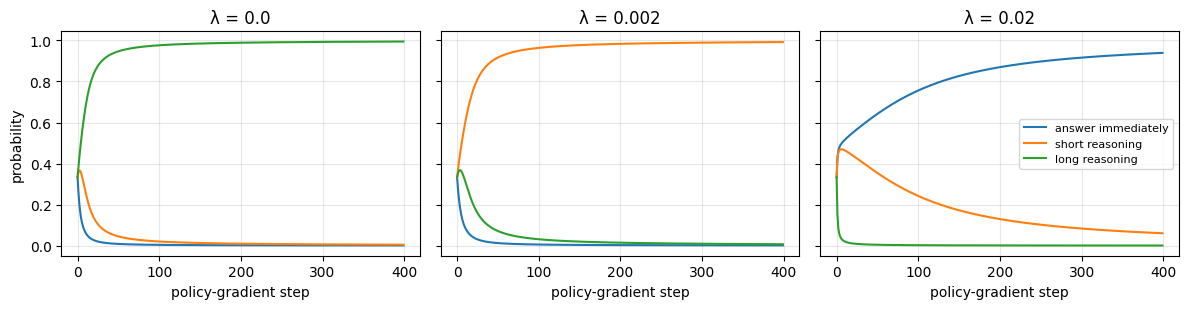

In [10]:
if plt is not None:
    fig, axes = plt.subplots(1, len(LAMS), figsize=(12, 3.2), sharey=True)
    for ax, lam in zip(axes, LAMS):
        hist, _ = runs[lam]
        for k, name in enumerate(NAMES):
            ax.plot(hist[:, k], label=name)
        ax.set_title(f"λ = {lam}")
        ax.set_xlabel("policy-gradient step")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("probability")
    axes[-1].legend(fontsize=8)
    fig.tight_layout()
    plt.show()
else:
    print("matplotlib not installed; skipping the plot")

At λ = 0 the mass flows to long reasoning (0.90 > 0.80). A small price (λ = 0.002) makes short reasoning the best
action, and a large one (λ = 0.02) makes answering immediately the best. The real system faces this trade-off per
question, which is why the routing has to be learned rather than fixed.

## 4. λ relabelling on a bundled sample of capability profiles

`notebooks/sample_labels.json` holds 60 profiled items per genre (statistics only, no question text):
`g` = genre, `b` = difficulty band, `p` = per-mode accuracy of base Qwen3-4B, `t` = mean generated tokens per
mode. The label is the mode with the highest utility U = p − λt (λ = 0.0005 for every reported run).
Accuracy gaps between modes are usually much larger than λ·t at λ = 0.0005 (100 tokens cost 5 points), so the
labels only move once tokens get expensive.

In [11]:
import collections

rows = json.loads((ROOT / "notebooks" / "sample_labels.json").read_text(encoding="utf-8"))
GENRES = sorted({r["g"] for r in rows})
print(len(rows), "items;", dict(collections.Counter(r["g"] for r in rows)))
print("example:", rows[0])

def suggested(r, lam):
    # argmax of U; on an exact tie the cheaper mode wins (jev < direct < cot)
    modes = [m for m in fmt.MODES if m in r["p"]]
    return max(modes, key=lambda m: r["p"][m] - lam * r["t"][m])

def shares(lam):
    out = {}
    for g in GENRES:
        picks = collections.Counter(suggested(r, lam) for r in rows if r["g"] == g)
        n = sum(picks.values())
        out[g] = {m: picks.get(m, 0) / n for m in fmt.MODES}
    return out

for lam in (0.0, 0.0005, 0.005):
    print(f"\nλ = {lam}: share of items labelled jev / direct / cot")
    for g, s in shares(lam).items():
        print(f"  {g:12} " + " / ".join(f"{s[m]:.0%}" for m in fmt.MODES))

360 items; {'arith': 60, 'compare': 60, 'decision': 60, 'knowledge': 60, 'rubric': 60, 'wordproblem': 60}
example: {'g': 'arith', 'b': 'digits=6', 'p': {'jev': 0.0, 'direct': 1.0, 'cot': 0.75}, 't': {'jev': 1.0, 'direct': 10.0, 'cot': 183.5}}

λ = 0.0: share of items labelled jev / direct / cot
  arith        8% / 28% / 63%
  compare      93% / 0% / 7%
  decision     90% / 7% / 3%
  knowledge    97% / 2% / 2%
  rubric       52% / 7% / 42%
  wordproblem  23% / 12% / 65%

λ = 0.0005: share of items labelled jev / direct / cot
  arith        8% / 28% / 63%
  compare      93% / 0% / 7%
  decision     90% / 7% / 3%
  knowledge    97% / 2% / 2%
  rubric       52% / 7% / 42%
  wordproblem  23% / 12% / 65%

λ = 0.005: share of items labelled jev / direct / cot
  arith        8% / 33% / 58%
  compare      93% / 0% / 7%
  decision     92% / 7% / 2%
  knowledge    97% / 2% / 2%
  rubric       52% / 7% / 42%
  wordproblem  30% / 18% / 52%


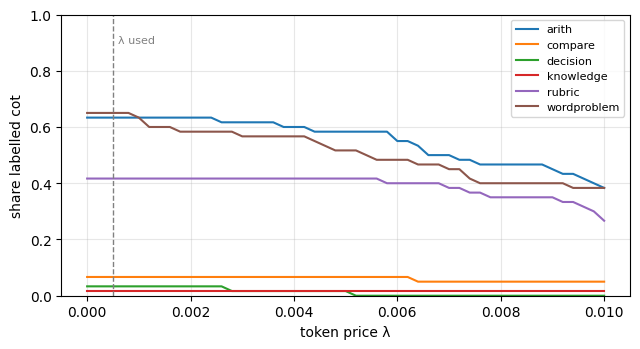

In [12]:
lams = np.linspace(0, 0.01, 51)
cot_share = {g: [shares(l)[g]["cot"] for l in lams] for g in GENRES}
if plt is not None:
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    for g in GENRES:
        ax.plot(lams, cot_share[g], label=g)
    ax.axvline(0.0005, color="gray", ls="--", lw=1)
    ax.text(0.0006, 0.9, "λ used", color="gray", fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_xlabel("token price λ")
    ax.set_ylabel("share labelled cot")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
else:
    for g in GENRES:
        print(g, [round(x, 2) for x in cot_share[g][::10]])

---
## Optional: a 3-step Tunix GRPO smoke run on a Colab / Kaggle TPU

**Not executed by default.** Set `RUN_TPU = True` on a TPU runtime (e.g. Colab TPU v5e-1 or a Kaggle TPU) to
install the `[tpu]` extra, write a tiny RL file from the procedural tasks, and run three GRPO steps of Qwen3-0.6B
with the real reward (`kwtfs.rewards`) and data module (`kwtfs.tasks`). It downloads Qwen3-0.6B from the Hugging
Face Hub and takes several minutes, mostly compilation. Nothing here creates cloud resources.

In [13]:
RUN_TPU = False  # set to True on a TPU runtime

In [14]:
import os, subprocess

if RUN_TPU:
    # Colab: clone first, e.g. !git clone https://github.com/TinevimboMusingadi/kwtfs-public && %cd kwtfs-public
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", f"{ROOT}[tpu]"], check=True)
    import jax
    print(jax.devices())
else:
    print("RUN_TPU is False: skipped")

RUN_TPU is False: skipped


In [15]:
if RUN_TPU:
    from kwtfs.data import sources

    smoke = pathlib.Path("/tmp/kwtfs/smoke")
    smoke.mkdir(parents=True, exist_ok=True)
    items = [it for it in sources.procedural(n_per_cell=2) if it.genre in ("compare", "arith")][:32]
    with open(smoke / "rl.jsonl", "w", encoding="utf-8") as f:
        for it in items:  # no measured utilities: route_regret is 0, the other terms are live
            f.write(json.dumps({"id": it.id, "question": it.question, "options": it.options,
                                "gold": it.gold, "genre": it.genre}) + "\n")
    env = dict(os.environ, KWT_RL_DATA=str(smoke / "rl.jsonl"), PYTHONPATH=str(ROOT))
    cmd = [sys.executable, "-m", "kwtfs.train.grpo", "--smoke", "--out", str(smoke / "out"),
           "rl_training_config.max_steps=3",
           f"rl_training_config.checkpoint_root_directory={smoke / 'ckpt'}"]
    print(" ".join(cmd))
    subprocess.run(cmd, env=env, check=True)  # prints one [step] routing line per rollout batch
    print(sorted(p.name for p in (smoke / "out").iterdir()))  # lora.npz, DONE
else:
    print("RUN_TPU is False: skipped")

RUN_TPU is False: skipped
